# Tugas Hands-On 3: Pandas Lanjutan – Employee Attrition

**Mata Kuliah:** Artificial Intelligence  
**Nama / NIM:** Nazwa Khoerunnisa / 23552011093  
**Kasus dipilih:** #05 Employee Attrition (HR Analytics), file `case5_employee_attrition.csv`, 1.200 baris  
**Jenis tugas:** klasifikasi biner, target `keluar_perusahaan` (Ya = keluar, Tidak = bertahan)


| Tahap | Isi |
|---|---|
| 1. Data | Muat data, `shape`, `info()`, `describe()` |
| 2. Kualitas | Audit dengan `cek_kualitas`, lalu bersihkan: duplikat → missing value → outlier per grup → tipe data |
| 3. Analisis | `groupby` lanjutan, `transform`, binning, pivot table, dan 3 temuan |
| 4. Persiapan model | Split `stratify`, feature creation, `ColumnTransformer`, feature selection, simpan CSV |
| 5. Kerapian | Checklist akhir |

**Aturan yang dipegang:** data mentah tidak diubah manual (semua lewat kode), dan **split dilakukan sebelum** imputasi, penanganan outlier, scaling, dan encoding. Semua nilai statistik (median, modus, batas IQR, mean, standar deviasi, kategori) hanya dihitung dari data train.

## Persiapan

In [1]:
import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
RANDOM_STATE = 42

# Struktur folder sesuai instruksi: data/ dan output/
os.makedirs('data', exist_ok=True)
os.makedirs('output', exist_ok=True)
print('Library berhasil diimport')

Library berhasil diimport


# Tahap 1: Data



In [2]:
FILE_DATA = 'data/case5_employee_attrition.csv'

if not os.path.exists(FILE_DATA):
    if os.path.exists('case5_employee_attrition.csv'):
        shutil.copy('case5_employee_attrition.csv', FILE_DATA)
    else:
        try:
            from google.colab import files
            print('Silakan unggah file CSV dataset...')
            terunggah = files.upload()
            shutil.move(list(terunggah.keys())[0], FILE_DATA)
        except ImportError:
            raise FileNotFoundError('Letakkan case5_employee_attrition.csv di folder data/')

df_mentah = pd.read_csv(FILE_DATA)     # data mentah, tidak pernah diubah
print('Ukuran data (baris, kolom):', df_mentah.shape)
df_mentah.head()

Silakan unggah file CSV dataset...


Saving case5_employee_attrition - case5_employee_attrition.csv.csv to case5_employee_attrition - case5_employee_attrition.csv.csv
Ukuran data (baris, kolom): (1200, 17)


,employee_id,usia,jenis_kelamin,departemen,jabatan,bidang_pendidikan,lama_di_perusahaan_tahun,lama_di_jabatan_tahun,gaji_bulanan_idr,lembur,kepuasan_kerja,keseimbangan_hidup_kerja,kepuasan_lingkungan,jumlah_perusahaan_sebelumnya,pelatihan_tahun_ini,rating_performa,keluar_perusahaan
0,EMP00001,33.0,Perempuan,IT,Data Engineer,IPS,11.0,11.0,15354728.0,Tidak,4.0,3.0,2.0,0.0,0.0,4.0,Tidak
1,EMP00002,53.0,Laki-laki,Operations,Manajer Logistik,NaN,2.0,2.0,26936991.0,Tidak,4.0,2.0,4.0,5.0,3.0,2.0,Tidak
2,EMP00003,52.0,Laki-laki,IT,Data Analyst,Bisnis,8.0,3.0,23169281.0,Tidak,1.0,NaN,3.0,1.0,2.0,1.0,Tidak
3,EMP00004,27.0,NaN,Sales,Sales Manager,IPS,0.0,0.0,40689975.0,Tidak,2.0,4.0,3.0,4.0,3.0,3.0,Tidak
4,EMP00005,43.0,Perempuan,HR,Recruiter,IPS,10.0,10.0,17935369.0,Ya,4.0,2.0,2.0,8.0,0.0,1.0,Ya


In [3]:
df_mentah.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   employee_id                   1200 non-null   object 
 1   usia                          1170 non-null   float64
 2   jenis_kelamin                 1172 non-null   object 
 3   departemen                    1169 non-null   object 
 4   jabatan                       1182 non-null   object 
 5   bidang_pendidikan             1152 non-null   object 
 6   lama_di_perusahaan_tahun      1176 non-null   float64
 7   lama_di_jabatan_tahun         1153 non-null   float64
 8   gaji_bulanan_idr              1161 non-null   float64
 9   lembur                        1162 non-null   object 
 10  kepuasan_kerja                1165 non-null   float64
 11  keseimbangan_hidup_kerja      1150 non-null   float64
 12  kepuasan_lingkungan           1145 non-null   float64
 13  jum

In [4]:
df_mentah.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
employee_id,1200,1200,EMP01184,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
usia,1170.0,NaN,NaN,NaN,39.446154,10.795997,21.0,31.0,39.0,49.0,58.0
jenis_kelamin,1172,2,Perempuan,608,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departemen,1169,5,Sales,266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jabatan,1182,17,Sales Representative,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bidang_pendidikan,1152,6,Teknik,213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lama_di_perusahaan_tahun,1176.0,NaN,NaN,NaN,10.356293,6.127699,0.0,5.0,11.0,16.0,20.0
lama_di_jabatan_tahun,1153.0,NaN,NaN,NaN,4.673894,3.557731,0.0,2.0,4.0,7.0,12.0
gaji_bulanan_idr,1161.0,NaN,NaN,NaN,34263088.179156,17821131.378277,4157623.0,18775091.0,34255942.0,49778960.0,64932189.0
lembur,1162,2,Tidak,665,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Distribusi target
print(df_mentah['keluar_perusahaan'].value_counts())
print(df_mentah['keluar_perusahaan'].value_counts(normalize=True).round(3))

keluar_perusahaan
Tidak    864
Ya       336
Name: count, dtype: int64
keluar_perusahaan
Tidak    0.72
Ya       0.28
Name: proportion, dtype: float64


# Tahap 2: Kualitas Data

## 2.1 Audit Awal dengan `cek_kualitas`

In [6]:
def cek_kualitas(d, kolom_num, kolom_grup, kunci):
    """Ringkasan kualitas data: baris, duplikat, missing, dan outlier IQR per grup."""
    g  = d.groupby(kolom_grup, observed=True)[kolom_num]
    q1 = g.transform(lambda s: s.quantile(0.25))
    q3 = g.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    outlier = (d[kolom_num] < q1 - 1.5 * iqr) | (d[kolom_num] > q3 + 1.5 * iqr)
    return pd.Series({
        'n_baris':    len(d),
        'n_duplikat': d.duplicated(subset=kunci).sum(),
        'n_missing':  d.isnull().sum().sum(),
        'n_outlier':  outlier.sum(),
    })

# kolom_num = gaji (satu-satunya kolom bernilai rupiah), kolom_grup = jabatan, kunci = employee_id
cek_kualitas(df_mentah, 'gaji_bulanan_idr', 'jabatan', 'employee_id')

,0
n_baris,1200
n_duplikat,0
n_missing,574
n_outlier,0


In [7]:
# a) Missing value per kolom
missing = pd.DataFrame({'n_missing': df_mentah.isnull().sum(),
                        'persen': (df_mentah.isnull().mean() * 100).round(2)})
print(missing[missing['n_missing'] > 0])
print('\nTotal sel kosong:', int(df_mentah.isnull().sum().sum()))

                              n_missing  persen
usia                                 30    2.50
jenis_kelamin                        28    2.33
departemen                           31    2.58
jabatan                              18    1.50
bidang_pendidikan                    48    4.00
lama_di_perusahaan_tahun             24    2.00
lama_di_jabatan_tahun                47    3.92
gaji_bulanan_idr                     39    3.25
lembur                               38    3.17
kepuasan_kerja                       35    2.92
keseimbangan_hidup_kerja             50    4.17
kepuasan_lingkungan                  55    4.58
jumlah_perusahaan_sebelumnya         40    3.33
pelatihan_tahun_ini                  56    4.67
rating_performa                      35    2.92

Total sel kosong: 574


In [8]:
# b) Duplikat: berdasarkan kunci, dan berdasarkan seluruh kolom selain ID
kolom_tanpa_id = [c for c in df_mentah.columns if c != 'employee_id']
print('Duplikat employee_id        :', df_mentah.duplicated(subset='employee_id').sum())
print('Duplikat seluruh kolom tanpa ID:', df_mentah.duplicated(subset=kolom_tanpa_id).sum())

# c) Outlier IQR per grup (jabatan) untuk 4 kolom numerik kontinu
kolom_outlier = ['usia', 'lama_di_perusahaan_tahun', 'lama_di_jabatan_tahun', 'gaji_bulanan_idr']
for k in kolom_outlier:
    print(f'Outlier per jabatan - {k}:', cek_kualitas(df_mentah, k, 'jabatan', 'employee_id')['n_outlier'])

Duplikat employee_id        : 0
Duplikat seluruh kolom tanpa ID: 0
Outlier per jabatan - usia: 0
Outlier per jabatan - lama_di_perusahaan_tahun: 0
Outlier per jabatan - lama_di_jabatan_tahun: 0
Outlier per jabatan - gaji_bulanan_idr: 0


In [9]:
# d) Validitas rentang dan label
kolom_skala = ['kepuasan_kerja', 'keseimbangan_hidup_kerja', 'kepuasan_lingkungan', 'rating_performa']
print(df_mentah.select_dtypes(include='number').agg(['min', 'max']).T)
print()
for c in ['jenis_kelamin', 'departemen', 'jabatan', 'bidang_pendidikan', 'lembur']:
    nilai = df_mentah[c].dropna()
    print(f'{c}: {nilai.nunique()} kategori, label dengan spasi berlebih: {(nilai != nilai.str.strip()).sum()}')

                                    min         max
usia                               21.0        58.0
lama_di_perusahaan_tahun            0.0        20.0
lama_di_jabatan_tahun               0.0        12.0
gaji_bulanan_idr              4157623.0  64932189.0
kepuasan_kerja                      1.0         4.0
keseimbangan_hidup_kerja            1.0         4.0
kepuasan_lingkungan                 1.0         4.0
jumlah_perusahaan_sebelumnya        0.0         9.0
pelatihan_tahun_ini                 0.0         6.0
rating_performa                     1.0         4.0

jenis_kelamin: 2 kategori, label dengan spasi berlebih: 0
departemen: 5 kategori, label dengan spasi berlebih: 0
jabatan: 17 kategori, label dengan spasi berlebih: 0
bidang_pendidikan: 6 kategori, label dengan spasi berlebih: 0
lembur: 2 kategori, label dengan spasi berlebih: 0


In [10]:
# e) Konsistensi logika antar kolom
peta = df_mentah.dropna(subset=['jabatan', 'departemen']).groupby('jabatan')['departemen'].nunique()
print('Jabatan yang muncul di >1 departemen:', (peta > 1).sum())

print('lama_di_jabatan > lama_di_perusahaan:',
      (df_mentah['lama_di_jabatan_tahun'] > df_mentah['lama_di_perusahaan_tahun']).sum())

usia_masuk = df_mentah['usia'] - df_mentah['lama_di_perusahaan_tahun']
usia_masuk_tidak_wajar = int((usia_masuk < 17).sum())
print(f'usia - lama_di_perusahaan < 17 (asumsi batas wajar): {usia_masuk_tidak_wajar} baris '
      f'({usia_masuk_tidak_wajar / len(df_mentah) * 100:.1f}%)')

Jabatan yang muncul di >1 departemen: 0
lama_di_jabatan > lama_di_perusahaan: 0
usia - lama_di_perusahaan < 17 (asumsi batas wajar): 207 baris (17.2%)


## Temuan Audit

Hasil pemeriksaan ditampilkan melalui kode pada bagian sebelumnya. Perhatikan jumlah missing value, duplikat, outlier, rentang nilai, dan konsistensi antar kolom.

Rencana penanganan:
- Duplikat: hapus baris duplikat berdasarkan seluruh kolom selain ID.
- Missing value: isi nilai kosong menggunakan median atau modus dari data train.
- Outlier: periksa empat kolom numerik kontinu menggunakan metode IQR per jabatan.
- Tipe data: sesuaikan kolom numerik dan kategori setelah proses pembersihan.
- Ketidaksesuaian logika: catat dan tangani hanya jika aturan perbaikannya dapat dijelaskan. Jangan mengubah nilai hanya berdasarkan dugaan.


## 2.2 Pembersihan (urutan: duplikat → missing → outlier → tipe data)

### a. Duplikat


In [11]:
jumlah_awal = len(df_mentah)
df = df_mentah.drop_duplicates(subset=kolom_tanpa_id).reset_index(drop=True)
duplikat_dibuang = jumlah_awal - len(df)
print('Baris duplikat yang dibuang:', duplikat_dibuang, '| ukuran data:', df.shape)

Baris duplikat yang dibuang: 0 | ukuran data: (1200, 17)


### Split Train–Test (sebelum imputasi dan outlier)



In [12]:
train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE,
                               stratify=df['keluar_perusahaan'])
train = train.copy()
test = test.copy()

print('Ukuran train:', train.shape, '| test:', test.shape)
print('Proporsi keluar (train):', train['keluar_perusahaan'].value_counts(normalize=True).round(3).to_dict())
print('Proporsi keluar (test) :', test['keluar_perusahaan'].value_counts(normalize=True).round(3).to_dict())

Ukuran train: (960, 17) | test: (240, 17)
Proporsi keluar (train): {'Tidak': 0.72, 'Ya': 0.28}
Proporsi keluar (test) : {'Tidak': 0.721, 'Ya': 0.279}


### b. Missing Value

| Kolom | Strategi | Alasan |
|---|---|---|
| `departemen` | Diisi dari `jabatan` | Hubungan 1-ke-1 sudah dibuktikan di audit |
| `jabatan` | Modus jabatan pada departemen yang sama | Tetap konsisten dengan departemen |
| `jenis_kelamin`, `bidang_pendidikan`, `lembur` | Modus | Kolom kategorikal |
| `usia`, `lama_di_perusahaan_tahun`, `lama_di_jabatan_tahun`, `gaji_bulanan_idr` | Median | Numerik kontinu, median tahan nilai ekstrem |
| Skala 1–4, `jumlah_perusahaan_sebelumnya`, `pelatihan_tahun_ini` | Modus | Nilai bulat/diskret, rata-rata atau median bisa menghasilkan angka yang tidak ada di skala |

Baris tidak dihapus karena missing per kolom hanya sekitar 1,5%–4,7%; menghapus baris akan membuang banyak data.

In [13]:
kolom_median = ['usia', 'lama_di_perusahaan_tahun', 'lama_di_jabatan_tahun', 'gaji_bulanan_idr']
kolom_modus_num = ['kepuasan_kerja', 'keseimbangan_hidup_kerja', 'kepuasan_lingkungan', 'rating_performa',
                   'jumlah_perusahaan_sebelumnya', 'pelatihan_tahun_ini']
kolom_modus_kat = ['jenis_kelamin', 'bidang_pendidikan', 'lembur']

# Nilai pengganti: HANYA dari data train
peta_jabatan_departemen = (train.dropna(subset=['jabatan', 'departemen'])
                                .drop_duplicates('jabatan').set_index('jabatan')['departemen'])
modus_departemen = train['departemen'].mode()[0]
modus_jabatan_per_dept = train.groupby('departemen')['jabatan'].agg(lambda s: s.mode()[0])
nilai_median = train[kolom_median].median()
nilai_modus = train[kolom_modus_num + kolom_modus_kat].mode().iloc[0]

missing_sebelum = pd.concat([train, test]).isnull().sum()

for d in (train, test):
    d['departemen'] = d['departemen'].fillna(d['jabatan'].map(peta_jabatan_departemen))
    d['departemen'] = d['departemen'].fillna(modus_departemen)      # jika jabatan juga kosong
    d['jabatan'] = d['jabatan'].fillna(d['departemen'].map(modus_jabatan_per_dept))
    d[kolom_median] = d[kolom_median].fillna(nilai_median)
    d[kolom_modus_num + kolom_modus_kat] = d[kolom_modus_num + kolom_modus_kat].fillna(nilai_modus)

print('Median (train):', nilai_median.to_dict())
print('Missing tersisa -> train:', train.isnull().sum().sum(), '| test:', test.isnull().sum().sum())

Median (train): {'usia': 38.0, 'lama_di_perusahaan_tahun': 11.0, 'lama_di_jabatan_tahun': 4.0, 'gaji_bulanan_idr': 33467519.0}
Missing tersisa -> train: 0 | test: 0


### c. Outlier per Grup (IQR per `jabatan`)



In [14]:
def batas_iqr(d, kolom, grup):
    g = d.groupby(grup, observed=True)[kolom]
    q1, q3 = g.quantile(0.25), g.quantile(0.75)
    iqr = q3 - q1
    return pd.DataFrame({'bawah': q1 - 1.5 * iqr, 'atas': q3 + 1.5 * iqr})

batas = {k: batas_iqr(train, k, 'jabatan') for k in kolom_outlier}   # dari train saja

jumlah_clip = {}
for k in kolom_outlier:
    jumlah_clip[k] = 0
    for d in (train, test):
        bawah = d['jabatan'].map(batas[k]['bawah'])
        atas = d['jabatan'].map(batas[k]['atas'])
        jumlah_clip[k] += int(((d[k] < bawah) | (d[k] > atas)).sum())
        d[k] = d[k].clip(lower=bawah, upper=atas)

print('Jumlah nilai yang di-clip per kolom:', jumlah_clip)

Jumlah nilai yang di-clip per kolom: {'usia': 0, 'lama_di_perusahaan_tahun': 0, 'lama_di_jabatan_tahun': 2, 'gaji_bulanan_idr': 0}


### d. Konsistensi Logika dan Tipe Data

- Karena `lama_di_perusahaan_tahun` dan `lama_di_jabatan_tahun` diisi median secara terpisah, bisa muncul baris dengan lama di jabatan lebih besar dari lama di perusahaan. Jika ada, nilainya dibatasi.
- Kolom yang tadinya `float64` karena ada NaN dikembalikan menjadi bilangan bulat.
- Kolom teks kategorikal diubah ke tipe `category`.

In [15]:
jumlah_cap = {}
for nama, d in (('train', train), ('test', test)):
    salah = d['lama_di_jabatan_tahun'] > d['lama_di_perusahaan_tahun']
    jumlah_cap[nama] = int(salah.sum())
    d['lama_di_jabatan_tahun'] = np.minimum(d['lama_di_jabatan_tahun'], d['lama_di_perusahaan_tahun'])
print('Baris lama_di_jabatan yang dibatasi akibat imputasi:', jumlah_cap)

kolom_angka = train.select_dtypes(include='number').columns.tolist()
kolom_kategori = ['jenis_kelamin', 'departemen', 'jabatan', 'bidang_pendidikan', 'lembur', 'keluar_perusahaan']
for d in (train, test):
    d[kolom_angka] = d[kolom_angka].round().astype('int64')
    d[kolom_kategori] = d[kolom_kategori].astype('category')

print()
print(train.dtypes)

Baris lama_di_jabatan yang dibatasi akibat imputasi: {'train': 6, 'test': 1}

employee_id                       object
usia                               int64
jenis_kelamin                   category
departemen                      category
jabatan                         category
bidang_pendidikan               category
lama_di_perusahaan_tahun           int64
lama_di_jabatan_tahun              int64
gaji_bulanan_idr                   int64
lembur                          category
kepuasan_kerja                     int64
keseimbangan_hidup_kerja           int64
kepuasan_lingkungan                int64
jumlah_perusahaan_sebelumnya       int64
pelatihan_tahun_ini                int64
rating_performa                    int64
keluar_perusahaan               category
dtype: object


## 2.3 Hasil: `df_bersih`, Tabel Sebelum vs Sesudah, dan Kamus Data

In [16]:
df_bersih = pd.concat([train, test]).sort_index()    # urutan baris kembali seperti data asli
df_bersih.head()

,employee_id,usia,jenis_kelamin,departemen,jabatan,bidang_pendidikan,lama_di_perusahaan_tahun,lama_di_jabatan_tahun,gaji_bulanan_idr,lembur,kepuasan_kerja,keseimbangan_hidup_kerja,kepuasan_lingkungan,jumlah_perusahaan_sebelumnya,pelatihan_tahun_ini,rating_performa,keluar_perusahaan
0,EMP00001,33,Perempuan,IT,Data Engineer,IPS,11,11,15354728,Tidak,4,3,2,0,0,4,Tidak
1,EMP00002,53,Laki-laki,Operations,Manajer Logistik,Teknik,2,2,26936991,Tidak,4,2,4,5,3,2,Tidak
2,EMP00003,52,Laki-laki,IT,Data Analyst,Bisnis,8,3,23169281,Tidak,1,4,3,1,2,1,Tidak
3,EMP00004,27,Perempuan,Sales,Sales Manager,IPS,0,0,40689975,Tidak,2,4,3,4,3,3,Tidak
4,EMP00005,43,Perempuan,HR,Recruiter,IPS,10,10,17935369,Ya,4,2,2,8,0,1,Ya


In [17]:
# Membandingkan kualitas data sebelum dan sesudah pembersihan.
# Outlier diperiksa pada empat kolom numerik kontinu dengan metode IQR per jabatan.

baris_laporan = []
for tahap, data in [('Sebelum', df_mentah), ('Sesudah', df_bersih)]:
    for kolom in kolom_outlier:
        hasil = cek_kualitas(data, kolom, 'jabatan', 'employee_id')
        baris_laporan.append({
            'tahap': tahap,
            'kolom_outlier': kolom,
            'jumlah_baris': hasil['n_baris'],
            'duplikat_id': hasil['n_duplikat'],
            'total_missing': hasil['n_missing'],
            'jumlah_outlier': hasil['n_outlier']
        })

laporan = pd.DataFrame(baris_laporan)
laporan.to_csv('laporan_kualitas.csv', index=False)
laporan


,tahap,kolom_outlier,jumlah_baris,duplikat_id,total_missing,jumlah_outlier
0,Sebelum,usia,1200,0,574,0
1,Sebelum,lama_di_perusahaan_tahun,1200,0,574,0
2,Sebelum,lama_di_jabatan_tahun,1200,0,574,0
3,Sebelum,gaji_bulanan_idr,1200,0,574,0
4,Sesudah,usia,1200,0,0,0
5,Sesudah,lama_di_perusahaan_tahun,1200,0,0,0
6,Sesudah,lama_di_jabatan_tahun,1200,0,0,0
7,Sesudah,gaji_bulanan_idr,1200,0,0,0


## Interpretasi Tabel Kualitas

- **n_baris** tetap 1.200: tidak ada baris yang dihapus (tidak ada duplikat, dan missing/outlier ditangani tanpa membuang baris).
- **n_duplikat** 0 sebelum dan sesudah: kunci `employee_id` memang unik.
- **n_missing** turun dari 574 menjadi 0, karena semua sel kosong diisi memakai statistik train.
- **n_outlier** 0 sebelum dan sesudah untuk gaji per jabatan. Pada tiga kolom kontinu lain, data mentah juga 0 outlier; setelah imputasi muncul 2 nilai `lama_di_jabatan_tahun` di luar batas IQR jabatannya dan di-*clip* (lihat sel outlier).

Masalah yang **tidak** hilang di tabel ini: 207 baris dengan `usia` vs `lama_di_perusahaan_tahun` yang janggal. Baris ini dibiarkan dan dicatat, karena nilai yang benar tidak diketahui.

In [18]:
# Ringkasan keputusan pembersihan per kolom (detail tambahan)
penanganan = {
    'employee_id': 'Kunci; tidak ada masalah',
    'usia': 'Imputasi median; 207 baris janggal vs lama_di_perusahaan dibiarkan',
    'jenis_kelamin': 'Imputasi modus',
    'departemen': 'Diisi dari jabatan (pemetaan 1-ke-1 dari train)',
    'jabatan': 'Imputasi modus pada departemen yang sama',
    'bidang_pendidikan': 'Imputasi modus',
    'lama_di_perusahaan_tahun': 'Imputasi median; 207 baris janggal vs usia dibiarkan',
    'lama_di_jabatan_tahun': 'Imputasi median; dibatasi maks. lama_di_perusahaan_tahun',
    'gaji_bulanan_idr': 'Imputasi median',
    'lembur': 'Imputasi modus',
    'kepuasan_kerja': 'Imputasi modus',
    'keseimbangan_hidup_kerja': 'Imputasi modus',
    'kepuasan_lingkungan': 'Imputasi modus',
    'jumlah_perusahaan_sebelumnya': 'Imputasi modus',
    'pelatihan_tahun_ini': 'Imputasi modus',
    'rating_performa': 'Imputasi modus',
    'keluar_perusahaan': 'Target lengkap; tidak ada masalah',
}
audit_kolom = pd.DataFrame({
    'tipe_sebelum': df_mentah.dtypes.astype(str),
    'tipe_sesudah': df_bersih.dtypes.astype(str),
    'missing_sebelum': df_mentah.isnull().sum(),
    'missing_sesudah': df_bersih.isnull().sum(),
    'penanganan': pd.Series(penanganan),
})
audit_kolom.index.name = 'kolom'
audit_kolom.to_csv('output/audit_per_kolom.csv')
audit_kolom

,tipe_sebelum,tipe_sesudah,missing_sebelum,missing_sesudah,penanganan
kolom,,,,,
employee_id,object,object,0,0,Kunci; tidak ada masalah
usia,float64,int64,30,0,Imputasi median; 207 baris janggal vs lama_di_...
jenis_kelamin,object,category,28,0,Imputasi modus
departemen,object,category,31,0,Diisi dari jabatan (pemetaan 1-ke-1 dari train)
jabatan,object,category,18,0,Imputasi modus pada departemen yang sama
bidang_pendidikan,object,category,48,0,Imputasi modus
lama_di_perusahaan_tahun,float64,int64,24,0,Imputasi median; 207 baris janggal vs usia dib...
lama_di_jabatan_tahun,float64,int64,47,0,Imputasi median; dibatasi maks. lama_di_perusa...
gaji_bulanan_idr,float64,int64,39,0,Imputasi median


In [19]:
# Kamus data (kolom, tipe, n_missing, n_unik) + deskripsi
deskripsi = {
    'employee_id': ('ID unik karyawan', 'kunci'),
    'usia': ('Usia karyawan (tahun)', 'fitur'),
    'jenis_kelamin': ('Jenis kelamin (Laki-laki / Perempuan)', 'fitur'),
    'departemen': ('Departemen tempat bekerja', 'fitur (tidak dipakai di model, redundan dengan jabatan)'),
    'jabatan': ('Jabatan karyawan', 'fitur'),
    'bidang_pendidikan': ('Bidang pendidikan karyawan', 'fitur'),
    'lama_di_perusahaan_tahun': ('Lama bekerja di perusahaan (tahun)', 'fitur'),
    'lama_di_jabatan_tahun': ('Lama di jabatan saat ini (tahun)', 'fitur'),
    'gaji_bulanan_idr': ('Gaji bulanan (Rupiah)', 'fitur'),
    'lembur': ('Apakah karyawan lembur (Ya / Tidak)', 'fitur'),
    'kepuasan_kerja': ('Skor kepuasan kerja, skala 1-4 (arti tiap angka tidak dijelaskan di dataset)', 'fitur'),
    'keseimbangan_hidup_kerja': ('Skor keseimbangan hidup-kerja, skala 1-4 (arti tiap angka tidak dijelaskan di dataset)', 'fitur'),
    'kepuasan_lingkungan': ('Skor kepuasan lingkungan kerja, skala 1-4 (arti tiap angka tidak dijelaskan di dataset)', 'fitur'),
    'jumlah_perusahaan_sebelumnya': ('Jumlah perusahaan tempat bekerja sebelumnya', 'fitur'),
    'pelatihan_tahun_ini': ('Pelatihan pada tahun ini (nilai 0-6)', 'fitur'),
    'rating_performa': ('Rating performa, skala 1-4 (arti tiap angka tidak dijelaskan di dataset)', 'fitur'),
    'keluar_perusahaan': ('Apakah karyawan keluar dari perusahaan (Ya / Tidak)', 'TARGET'),
}
kamus_data = pd.DataFrame({
    'kolom': df_bersih.columns,
    'tipe': df_bersih.dtypes.astype(str).values,
    'n_missing': df_bersih.isnull().sum().values,
    'n_unik': df_bersih.nunique().values,
})
kamus_data['deskripsi'] = kamus_data['kolom'].map(lambda k: deskripsi[k][0])
kamus_data['peran'] = kamus_data['kolom'].map(lambda k: deskripsi[k][1])
kamus_data['n_missing_mentah'] = kamus_data['kolom'].map(df_mentah.isnull().sum())

df_bersih.to_csv('output/data_bersih.csv', index=False)
kamus_data.to_csv('output/kamus_data.csv', index=False)
print('Tersimpan: output/data_bersih.csv dan output/kamus_data.csv')
kamus_data

Tersimpan: output/data_bersih.csv dan output/kamus_data.csv


,kolom,tipe,n_missing,n_unik,deskripsi,peran,n_missing_mentah
0,employee_id,object,0,1200,ID unik karyawan,kunci,0
1,usia,int64,0,38,Usia karyawan (tahun),fitur,30
2,jenis_kelamin,category,0,2,Jenis kelamin (Laki-laki / Perempuan),fitur,28
3,departemen,category,0,5,Departemen tempat bekerja,"fitur (tidak dipakai di model, redundan dengan...",31
4,jabatan,category,0,17,Jabatan karyawan,fitur,18
5,bidang_pendidikan,category,0,6,Bidang pendidikan karyawan,fitur,48
6,lama_di_perusahaan_tahun,int64,0,21,Lama bekerja di perusahaan (tahun),fitur,24
7,lama_di_jabatan_tahun,int64,0,13,Lama di jabatan saat ini (tahun),fitur,47
8,gaji_bulanan_idr,int64,0,1162,Gaji bulanan (Rupiah),fitur,39
9,lembur,category,0,2,Apakah karyawan lembur (Ya / Tidak),fitur,38


# Tahap 3: Analisis

Analisis memakai `df_bersih` dan hanya bersifat deskriptif (tidak dipakai untuk menghitung nilai preprocessing).

**Bagian yang dilewati, dengan alasan:**
- *Tren waktu:* dataset tidak memiliki kolom tanggal.
- *RFM:* RFM butuh data transaksi per pelanggan (recency, frequency, monetary), sedangkan dataset ini satu baris per karyawan tanpa transaksi.

In [20]:
df_a = df_bersih.copy()
df_a['keluar'] = (df_a['keluar_perusahaan'] == 'Ya').astype(int)   # 1 = keluar
df_a['lembur_ya'] = (df_a['lembur'] == 'Ya').astype(int)
print('Tingkat keluar keseluruhan:', round(df_a['keluar'].mean() * 100, 1), '%')

Tingkat keluar keseluruhan: 28.0 %


## 3.1 `groupby` + `agg` per Jabatan dan Departemen

In [21]:
ringkas_jabatan = df_a.groupby('jabatan', observed=True).agg(
    jumlah_karyawan     = ('employee_id', 'count'),
    persen_keluar       = ('keluar', 'mean'),
    persen_lembur       = ('lembur_ya', 'mean'),
    rata_kepuasan_kerja = ('kepuasan_kerja', 'mean'),
    rata_gaji_juta      = ('gaji_bulanan_idr', lambda s: s.mean() / 1e6),
)
ringkas_jabatan['persen_keluar'] = ringkas_jabatan['persen_keluar'] * 100
ringkas_jabatan['persen_lembur'] = ringkas_jabatan['persen_lembur'] * 100
ringkas_jabatan = ringkas_jabatan.round(1).sort_values('persen_keluar', ascending=False)
ringkas_jabatan

,jumlah_karyawan,persen_keluar,persen_lembur,rata_kepuasan_kerja,rata_gaji_juta
jabatan,,,,,
Sales Manager,85,40.0,38.8,2.6,36.0
Budget Controller,91,34.1,48.4,2.3,33.2
Data Engineer,42,33.3,50.0,2.5,32.4
Recruiter,79,32.9,36.7,2.8,35.3
DevOps,53,32.1,41.5,2.7,33.8
Training Specialist,64,31.2,53.1,2.7,35.6
Data Analyst,47,29.8,40.4,2.6,36.0
Financial Analyst,81,28.4,40.7,2.6,32.5
Staff Operasional,83,27.7,42.2,2.4,34.5


In [22]:
ringkas_dept = df_a.groupby('departemen', observed=True).agg(
    jumlah_karyawan = ('employee_id', 'count'),
    persen_keluar   = ('keluar', lambda s: s.mean() * 100),
    persen_lembur   = ('lembur_ya', lambda s: s.mean() * 100),
).round(1).sort_values('persen_keluar', ascending=False)
ringkas_dept

,jumlah_karyawan,persen_keluar,persen_lembur
departemen,,,
Finance,250,29.6,42.4
Sales,274,29.6,42.7
HR,203,28.6,42.4
IT,236,28.0,40.7
Operations,237,24.1,38.8


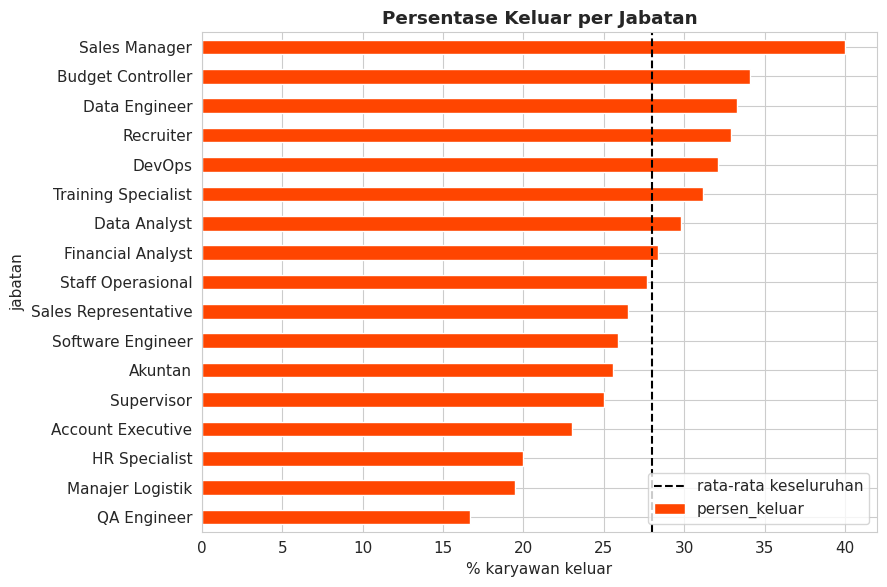

In [23]:
plt.figure(figsize=(9, 6))
ringkas_jabatan['persen_keluar'].sort_values().plot(kind='barh', color='#FF4500', edgecolor='white')
plt.axvline(df_a['keluar'].mean() * 100, color='black', linestyle='--', label='rata-rata keseluruhan')
plt.xlabel('% karyawan keluar')
plt.title('Persentase Keluar per Jabatan', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

## 3.2 `transform`: Gaji Relatif terhadap Rata-rata Jabatan

`transform('mean')` mengembalikan rata-rata per jabatan dengan jumlah baris yang sama, sehingga bisa dipakai membagi gaji tiap karyawan. Nilai 1,0 berarti gajinya sama dengan rata-rata jabatannya. Ini hanya untuk analisis; tidak dipakai sebagai fitur model (karena memakai rata-rata seluruh data).

In [24]:
df_a['gaji_relatif_jabatan'] = df_a['gaji_bulanan_idr'] / df_a.groupby('jabatan', observed=True)['gaji_bulanan_idr'].transform('mean')
df_a['kelompok_gaji_relatif'] = pd.qcut(df_a['gaji_relatif_jabatan'], q=4,
                                        labels=['Q1 (terendah)', 'Q2', 'Q3', 'Q4 (tertinggi)'])
df_a.groupby('kelompok_gaji_relatif', observed=True).agg(
    jumlah_karyawan=('employee_id', 'count'),
    persen_keluar=('keluar', lambda s: s.mean() * 100)).round(1)

,jumlah_karyawan,persen_keluar
kelompok_gaji_relatif,,
Q1 (terendah),300,30.7
Q2,300,28.3
Q3,300,23.0
Q4 (tertinggi),300,30.0


## 3.3 Binning: `pd.cut` untuk Usia dan Masa Kerja

In [25]:
df_a['kelompok_usia'] = pd.cut(df_a['usia'], bins=[20, 30, 40, 50, 60], labels=['21-30', '31-40', '41-50', '51-60'])
df_a['kelompok_masa_kerja'] = pd.cut(df_a['lama_di_perusahaan_tahun'], bins=[-1, 5, 10, 15, 20],
                                     labels=['0-5 th', '6-10 th', '11-15 th', '16-20 th'])
for kol in ['kelompok_usia', 'kelompok_masa_kerja']:
    print(df_a.groupby(kol, observed=True).agg(
        jumlah_karyawan=('employee_id', 'count'),
        persen_keluar=('keluar', lambda s: s.mean() * 100)).round(1))
    print()

               jumlah_karyawan  persen_keluar
kelompok_usia                                
21-30                      284           30.6
31-40                      381           26.8
41-50                      293           27.6
51-60                      242           27.3

                     jumlah_karyawan  persen_keluar
kelompok_masa_kerja                                
0-5 th                           322           28.0
6-10 th                          261           23.8
11-15 th                         298           31.2
16-20 th                         319           28.5



## 3.4 Pivot Table: Lembur × Kepuasan Kerja

Jumlah karyawan per sel:
kepuasan_kerja    1    2    3    4
lembur                            
Tidak           157  164  185  197
Ya              121  108  123  145



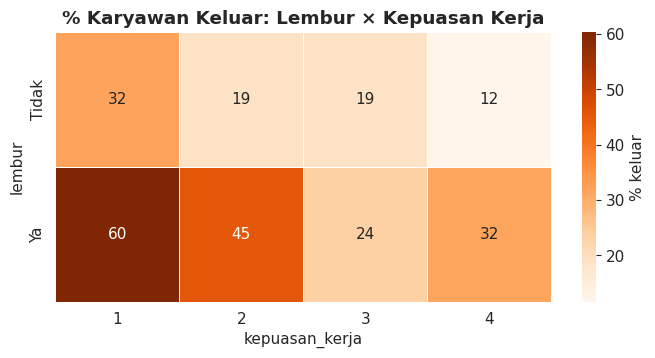

In [26]:
pivot_persen = pd.pivot_table(df_a, values='keluar', index='lembur', columns='kepuasan_kerja',
                              aggfunc='mean', observed=True) * 100
pivot_jumlah = pd.pivot_table(df_a, values='keluar', index='lembur', columns='kepuasan_kerja',
                              aggfunc='count', observed=True)
print('Jumlah karyawan per sel:'); print(pivot_jumlah); print()

plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot_persen, annot=True, fmt='.0f', cmap='Oranges', linewidths=0.5,
            cbar_kws={'label': '% keluar'})
plt.title('% Karyawan Keluar: Lembur × Kepuasan Kerja', fontweight='bold')
plt.show()

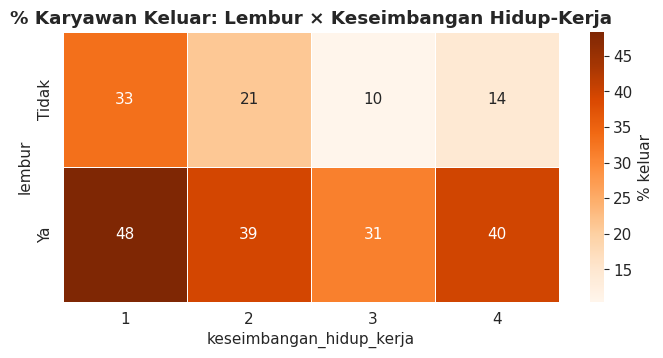

In [27]:
pivot2 = pd.pivot_table(df_a, values='keluar', index='lembur', columns='keseimbangan_hidup_kerja',
                        aggfunc='mean', observed=True) * 100
plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot2, annot=True, fmt='.0f', cmap='Oranges', linewidths=0.5,
            cbar_kws={'label': '% keluar'})
plt.title('% Karyawan Keluar: Lembur × Keseimbangan Hidup-Kerja', fontweight='bold')
plt.show()

In [28]:
# Ringkasan angka utama untuk temuan
print('% keluar - lembur Ya  :', round(df_a.loc[df_a['lembur'] == 'Ya', 'keluar'].mean() * 100, 1))
print('% keluar - lembur Tidak:', round(df_a.loc[df_a['lembur'] == 'Tidak', 'keluar'].mean() * 100, 1))
print()
print('% keluar per skor kepuasan_kerja:')
print((df_a.groupby('kepuasan_kerja', observed=True)['keluar'].mean() * 100).round(1))

% keluar - lembur Ya  : 39.6
% keluar - lembur Tidak: 19.8

% keluar per skor kepuasan_kerja:
kepuasan_kerja
1    44.2
2    29.4
3    20.8
4    20.2
Name: keluar, dtype: float64


## Tiga Temuan yang Bisa Ditindaklanjuti

1. **Lembur dan kepuasan kerja rendah saling memperkuat.** Karyawan yang lembur keluar sekitar 40% (vs sekitar 20% yang tidak lembur). Pada karyawan lembur dengan `kepuasan_kerja` = 1, tingkat keluar mencapai sekitar **60%** (121 orang), sedangkan karyawan tanpa lembur dengan `kepuasan_kerja` = 4 hanya sekitar **12%** (197 orang). *Tindak lanjut:* HR memprioritaskan pemantauan dan pengurangan lembur bagi karyawan berkepuasan kerja skor 1–2.
2. **Lembur tetap berkaitan dengan keluar meski keseimbangan hidup-kerja baik.** Karyawan lembur dengan `keseimbangan_hidup_kerja` = 4 keluar sekitar 40%, lebih tinggi daripada karyawan tanpa lembur dengan skor 1 (sekitar 33%). *Tindak lanjut:* kebijakan lembur perlu ditinjau langsung, tidak cukup hanya mengandalkan survei keseimbangan hidup-kerja.
3. **Tingkat keluar berbeda antar jabatan.** Tertinggi: Sales Manager sekitar 40% (85 orang), Budget Controller 34% (91), dan Data Engineer 33% (42). Terendah: QA Engineer 17% (36) dan Manajer Logistik 20% (82). *Tindak lanjut:* tinjau beban kerja dan kepuasan pada jabatan teratas lebih dulu. Karena tiap jabatan hanya puluhan sampai sekitar 100 orang, ini sebaiknya dikonfirmasi dengan data tambahan sebelum dijadikan keputusan.

kelompok usia, masa kerja, gaji relatif terhadap jabatan, dan departemen tidak menunjukkan pola yang jelas (tingkat keluar hanya berkisar sekitar 23%–31%). Jadi upaya retensi lebih masuk akal difokuskan pada lembur dan kepuasan kerja daripada segmentasi usia atau masa kerja. Semua temuan ini adalah hubungan statistik, bukan bukti sebab-akibat.

# Tahap 4: Persiapan Model

## 4.1 Feature Creation

Satu fitur baru dibuat dari tiga indikator yang sudah tersedia. Fitur ini merangkum kepuasan karyawan secara umum.

| Fitur baru | Rumus | Maksud |
|---|---|---|
| `rata_kepuasan` | Rata-rata `kepuasan_kerja`, `keseimbangan_hidup_kerja`, dan `kepuasan_lingkungan` | Ringkasan tiga indikator kepuasan kerja |

Fitur dihitung dari kolom yang sudah dibersihkan dan tidak menggunakan target. Perhitungan dilakukan per baris, bukan menggunakan statistik gabungan train dan test.


In [29]:
def buat_fitur(data):
    data = data.copy()
    # Rata-rata tiga indikator kepuasan kerja.
    data['rata_kepuasan'] = data[
        ['kepuasan_kerja', 'keseimbangan_hidup_kerja', 'kepuasan_lingkungan']
    ].mean(axis=1)
    return data

train_f = buat_fitur(train)
test_f = buat_fitur(test)

print('Contoh fitur baru:')
train_f[['kepuasan_kerja', 'keseimbangan_hidup_kerja',
         'kepuasan_lingkungan', 'rata_kepuasan']].head()


Contoh fitur baru:


,kepuasan_kerja,keseimbangan_hidup_kerja,kepuasan_lingkungan,rata_kepuasan
1025,3,1,3,2.333333
145,1,4,1,2.000000
1064,3,3,1,2.333333
797,4,1,3,2.666667
30,4,3,2,3.000000


## 4.2 Memilih Kolom, Target, dan Encoding Target

Kolom yang **tidak dipakai** sebagai fitur (beserta alasannya):

| Kolom | Alasan |
|---|---|
| `employee_id` | Kolom identitas/kunci, bukan karakteristik karyawan |
| `departemen` | Redundan: setiap jabatan hanya ada di satu departemen, jadi informasinya sudah ada di `jabatan` |

In [30]:
kolom_dibuang = {'employee_id': 'kolom identitas/kunci',
                 'departemen': 'redundan dengan jabatan (1 jabatan = 1 departemen)'}
kolom_target = 'keluar_perusahaan'

X_train = train_f.drop(columns=[kolom_target] + list(kolom_dibuang))
X_test = test_f.drop(columns=[kolom_target] + list(kolom_dibuang))

le = LabelEncoder()
y_train = pd.Series(le.fit_transform(train_f[kolom_target]), index=train_f.index, name=kolom_target)
y_test = pd.Series(le.transform(test_f[kolom_target]), index=test_f.index, name=kolom_target)
print('Encoding target:', {k: int(v) for v, k in enumerate(le.classes_)})
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

Encoding target: {'Tidak': 0, 'Ya': 1}
X_train: (960, 15) | X_test: (240, 15)


## 4.3 `ColumnTransformer` (tanpa Leakage)

| Kelompok | Kolom | Perlakuan |
|---|---|---|
| Numerik | `usia`, `lama_di_perusahaan_tahun`, `lama_di_jabatan_tahun`, `gaji_bulanan_idr`, `jumlah_perusahaan_sebelumnya`, `pelatihan_tahun_ini` | `StandardScaler` |
| Kategorikal biner | `jenis_kelamin`, `lembur` | `OneHotEncoder(drop='if_binary')` |
| Kategorikal lebih dari dua kelas | `jabatan`, `bidang_pendidikan` | `OneHotEncoder(drop='first')` |
| Skala 1–4 dan fitur ringkasan | `kepuasan_kerja`, `keseimbangan_hidup_kerja`, `kepuasan_lingkungan`, `rating_performa`, `rata_kepuasan` | Dibiarkan (`passthrough`) karena rentangnya sudah kecil dan seragam |

`fit_transform` hanya dilakukan pada **data train**, sedangkan data test hanya menggunakan `transform`. Dengan demikian, parameter scaler dan encoder tidak dipelajari dari data test.


In [31]:
# Kelompok kolom berdasarkan perlakuan yang akan diberikan.
kolom_scale = [
    'usia', 'lama_di_perusahaan_tahun', 'lama_di_jabatan_tahun',
    'gaji_bulanan_idr', 'jumlah_perusahaan_sebelumnya', 'pelatihan_tahun_ini'
]
kolom_biner = ['jenis_kelamin', 'lembur']
kolom_ohe = ['jabatan', 'bidang_pendidikan']
kolom_lewat = [
    'kepuasan_kerja', 'keseimbangan_hidup_kerja',
    'kepuasan_lingkungan', 'rating_performa', 'rata_kepuasan'
]

# Memastikan semua kolom fitur sudah masuk ke salah satu kelompok.
assert sorted(kolom_scale + kolom_biner + kolom_ohe + kolom_lewat) == sorted(X_train.columns)

ct = ColumnTransformer([
    ('scale', StandardScaler(), kolom_scale),
    ('biner', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), kolom_biner),
    ('kategori', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), kolom_ohe),
    ('lewat', 'passthrough', kolom_lewat),
], verbose_feature_names_out=False)

# Fit hanya menggunakan data train; data test hanya ditransformasi.
X_train_t = pd.DataFrame(
    ct.fit_transform(X_train),
    columns=ct.get_feature_names_out(),
    index=X_train.index
)
X_test_t = pd.DataFrame(
    ct.transform(X_test),
    columns=ct.get_feature_names_out(),
    index=X_test.index
)

print('Ukuran X_train:', X_train_t.shape)
print('Ukuran X_test :', X_test_t.shape)
print('Nama kolom train dan test sama:',
      list(X_train_t.columns) == list(X_test_t.columns))
print('Total missing setelah transformasi:',
      X_train_t.isnull().sum().sum() + X_test_t.isnull().sum().sum())

X_train_t.head()


Ukuran X_train: (960, 34)
Ukuran X_test : (240, 34)
Nama kolom train dan test sama: True
Total missing setelah transformasi: 0


,usia,lama_di_perusahaan_tahun,lama_di_jabatan_tahun,gaji_bulanan_idr,jumlah_perusahaan_sebelumnya,pelatihan_tahun_ini,jenis_kelamin_Perempuan,lembur_Ya,jabatan_Akuntan,jabatan_Budget Controller,jabatan_Data Analyst,jabatan_Data Engineer,jabatan_DevOps,jabatan_Financial Analyst,jabatan_HR Specialist,jabatan_Manajer Logistik,jabatan_QA Engineer,jabatan_Recruiter,jabatan_Sales Manager,jabatan_Sales Representative,jabatan_Software Engineer,jabatan_Staff Operasional,jabatan_Supervisor,jabatan_Training Specialist,bidang_pendidikan_IPA,bidang_pendidikan_IPS,bidang_pendidikan_Kedokteran,bidang_pendidikan_Sains,bidang_pendidikan_Teknik,kepuasan_kerja,keseimbangan_hidup_kerja,kepuasan_lingkungan,rating_performa,rata_kepuasan
1025,-0.198026,1.247193,-1.308136,-1.317405,1.199929,1.555262,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,3.0,1.0,3.0,2.0,2.333333
145,-1.335244,1.247193,0.397742,0.073770,1.551127,-0.494225,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,4.0,1.0,1.0,2.000000
1064,0.181047,-1.563771,-1.023823,-0.093089,0.848730,-1.518969,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,3.0,1.0,4.0,2.333333
797,0.560119,-0.902368,-0.170884,1.399553,1.551127,0.018147,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,1.0,3.0,1.0,2.666667
30,0.275815,0.255088,0.113429,-1.657945,-1.258462,1.555262,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,4.0,3.0,2.0,2.0,3.000000


In [32]:
# Pengecekan sederhana hasil standardisasi.
# Rata-rata train mendekati 0 dan standar deviasi train mendekati 1.
hasil_scaling = pd.DataFrame({
    'rata_rata_train': X_train_t[kolom_scale].mean(),
    'standar_deviasi_train': X_train_t[kolom_scale].std()
})
hasil_scaling.round(2)


,rata_rata_train,standar_deviasi_train
usia,0.0,1.0
lama_di_perusahaan_tahun,0.0,1.0
lama_di_jabatan_tahun,0.0,1.0
gaji_bulanan_idr,0.0,1.0
jumlah_perusahaan_sebelumnya,0.0,1.0
pelatihan_tahun_ini,0.0,1.0


## 4.4 Simpan Data Siap Model

Data train dan test yang sudah melalui `ColumnTransformer` disimpan sebagai satu file. Kolom `set_data` menandai asal baris sehingga pemisahan train dan test tetap dapat dikenali.


In [33]:
train_siap = X_train_t.assign(
    **{kolom_target: y_train, 'set_data': 'train'}
)
test_siap = X_test_t.assign(
    **{kolom_target: y_test, 'set_data': 'test'}
)

data_siap_model = pd.concat([train_siap, test_siap]).sort_index()

data_siap_model.to_csv('output/data_siap_model.csv', index=False)
print('File tersimpan: output/data_siap_model.csv')
print('Ukuran data:', data_siap_model.shape)
data_siap_model.head()


File tersimpan: output/data_siap_model.csv
Ukuran data: (1200, 36)


,usia,lama_di_perusahaan_tahun,lama_di_jabatan_tahun,gaji_bulanan_idr,jumlah_perusahaan_sebelumnya,pelatihan_tahun_ini,jenis_kelamin_Perempuan,lembur_Ya,jabatan_Akuntan,jabatan_Budget Controller,jabatan_Data Analyst,jabatan_Data Engineer,jabatan_DevOps,jabatan_Financial Analyst,jabatan_HR Specialist,jabatan_Manajer Logistik,jabatan_QA Engineer,jabatan_Recruiter,jabatan_Sales Manager,jabatan_Sales Representative,jabatan_Software Engineer,jabatan_Staff Operasional,jabatan_Supervisor,jabatan_Training Specialist,bidang_pendidikan_IPA,bidang_pendidikan_IPS,bidang_pendidikan_Kedokteran,bidang_pendidikan_Sains,bidang_pendidikan_Teknik,kepuasan_kerja,keseimbangan_hidup_kerja,kepuasan_lingkungan,rating_performa,rata_kepuasan,keluar_perusahaan,set_data
0,-0.577099,0.089737,1.819308,-1.059135,-1.609660,-1.518969,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0,3.0,2.0,4.0,3.000000,0,train
1,1.318264,-1.398420,-0.739510,-0.398717,0.146333,0.018147,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0,2.0,4.0,2.0,3.333333,0,test
2,1.223496,-0.406315,-0.455197,-0.613551,-1.258462,-0.494225,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0,3.0,1.0,2.666667,0,train
3,-1.145707,-1.729122,-1.308136,0.385476,-0.204866,0.018147,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0,4.0,3.0,3.0,3.000000,0,train
4,0.370583,-0.075614,1.534995,-0.911988,1.199929,-1.518969,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,4.0,2.0,2.0,1.0,2.666667,1,train


File `output/data_siap_model.csv` berisi fitur yang sudah diproses, target yang telah diubah menjadi angka, dan penanda `set_data` untuk membedakan train dan test. File ini merupakan keluaran tambahan untuk menunjukkan hasil persiapan data model; tugas ini belum sampai pada pelatihan atau evaluasi model.


# Tahap 5: Kerapian dan Checklist Akhir

In [34]:
print('CHECKLIST')
print('-' * 60)
print('[v] Data mentah tidak diubah manual   :', len(df_mentah), 'baris tetap di df_mentah')
print('[v] Tabel kualitas sebelum vs sesudah  : laporan_kualitas.csv')
print('[v] Data bersih dan kamus data         : output/')
print('[v] Split sebelum imputasi/outlier/scaling/encoding (random_state=42, stratify)')
print('[v] Imputer, batas IQR, scaler, encoder: hanya di-fit pada train')
print(f'[v] Missing value setelah pembersihan  : {int(df_bersih.isnull().sum().sum())}')
print()
print('File hasil:')
for f in ['laporan_kualitas.csv', 'output/data_bersih.csv',
          'output/kamus_data.csv', 'output/audit_per_kolom.csv',
          'output/data_siap_model.csv']:
    print(' -', f, '(ada)' if os.path.exists(f) else '(TIDAK ADA)')


CHECKLIST
------------------------------------------------------------
[v] Data mentah tidak diubah manual   : 1200 baris tetap di df_mentah
[v] Tabel kualitas sebelum vs sesudah  : laporan_kualitas.csv
[v] Data bersih dan kamus data         : output/
[v] Split sebelum imputasi/outlier/scaling/encoding (random_state=42, stratify)
[v] Imputer, batas IQR, scaler, encoder: hanya di-fit pada train
[v] Missing value setelah pembersihan  : 0

File hasil:
 - laporan_kualitas.csv (ada)
 - output/data_bersih.csv (ada)
 - output/kamus_data.csv (ada)
 - output/audit_per_kolom.csv (ada)
 - output/data_siap_model.csv (ada)


## Kesimpulan

1. Dataset berisi 1.200 karyawan. Proses audit dan pembersihan dilakukan dengan memeriksa duplikat, missing value, outlier, tipe data, serta konsistensi antar kolom.
2. Nilai kosong ditangani tanpa menghapus baris. Terdapat beberapa kombinasi usia dan lama bekerja yang perlu dikonfirmasi kepada pemilik data karena nilai yang benar tidak dapat dipastikan dari dataset.
3. Analisis menggunakan `groupby`, `agg`, `transform`, pengelompokan dengan `pd.cut`, dan `pivot_table` untuk melihat pola karyawan yang keluar.
4. Persiapan model dilakukan melalui pembagian data train-test dengan `stratify`, pembuatan satu fitur ringkasan kepuasan, dan `ColumnTransformer`. Proses imputasi, penentuan batas IQR, scaling, serta encoding menggunakan informasi dari data train.
5. Hasil analisis menunjukkan hubungan antara lembur, kepuasan kerja, dan keluarnya karyawan. Hubungan tersebut bersifat statistik dan tidak membuktikan sebab-akibat.


In [35]:
# (Opsional di Google Colab) unduh seluruh file hasil utama
try:
    from google.colab import files
    for f in ['laporan_kualitas.csv',
              'output/data_bersih.csv',
              'output/kamus_data.csv',
              'output/audit_per_kolom.csv',
              'output/data_siap_model.csv']:
        if os.path.exists(f):
            files.download(f)
except ImportError:
    print('Bukan di Google Colab: file tersimpan di folder kerja.')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>